# Лабораторная работа 5 Запуск открытой модели text-to-image

**Вариант 3 — бриф «афиша фестиваля робототехники», генератор CPU и CUDA при seed 1003.**

Власюк Данил Витальевич, группа Т26ИИКТ-МИК11.

Работа выполняется по приложенной методичке ЛР5 в Google Colab с NVIDIA GPU. Сначала выбрать Runtime → Change runtime type → T4 GPU, затем Run all. Сравнивается устройство **генератора начального шума**; вычисления модели в обоих условиях остаются на одном GPU. Выполняются оба предоставленных скрипта, индивидуальный вариант, повтор со свежим генератором, намеренная ошибка с общим генератором и контроль причины различий. Все численные результаты появляются только после выполнения.

Индивидуальный вклад: постановка гипотезы, протокол A/B, сохранение манифестов и начального шума, проверка повторяемости, независимый контроль, анализ и визуальная оценка. Исходная библиотека преподавателя сохранена без изменения.

## Итоговая таблица и визуальная оценка варианта 3

Результаты фактического запуска 26 октября 2026 года на Tesla T4. A — генератор CPU; B — генератор CUDA. Модель в обоих условиях вычислялась на одном GPU, seed 1003, fp16, один шаг, guidance=0, размер 512×512.

| Проверка | Результат |
| --- | --- |
| SHA-256 A | `098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08` |
| SHA-256 B | `4675318261e6f52dde480c450f4ecd10b4098544949930eed1c25179474f1e83` |
| Пиксели A и B совпадают | Нет |
| Максимальное различие канала | 255 из 255 |
| MSE | 7301.234217325847 |
| PSNR | 9.496840804095045 дБ |
| Вердикт при пороге 40 дБ | `different` — изображения различаются |
| Повтор со свежим CPU-генератором | Точное совпадение A |
| Два вызова с общим CPU-генератором | Различаются, PSNR 10.030305190015824 дБ |
| Два вызова с одним явным начальным шумом | Точное совпадение |

**Визуальная оценка.** В A (слева) изображён янтарный робот на тёмно-синем фоне, в B (справа) — синий робот на янтарном фоне. В обоих результатах узнаваемы механические руки и шарниры, сохранена основная цветовая палитра. Однако главным объектом стал целый многорукий робот, а не отдельный силуэт механической руки. Поэтому дополнительное требование к композиции выполнено **частично**. Деформированные конечности также ограничивают использование этих изображений как иллюстраций реальной техники. Явного читаемого текста и узнаваемых логотипов при осмотре не обнаружено.

Визуальное соответствие брифу и численная воспроизводимость — разные проверки. Низкий PSNR и различие композиций подтверждают гипотезу о разных результатах CPU/CUDA, но не означают, что одно изображение красивее другого. Нельзя заменить установленный seed или переписать prompt только ради более удачной картинки и считать это той же парой A/B.

**Причина различий.** CPU и CUDA сформировали разные тензоры до модели: максимальное различие 5.564453125, MSE 2.0380618572235107. При одинаковом явном шуме результат сети повторился точно и воспроизвёл A. Проверка согласуется с различием генераторов начального шума в данных условиях; она не доказывает универсальную побитовую воспроизводимость на любых GPU и версиях.

Порог 40 дБ и гипотеза записаны 21.10.2026, до генерации 26.10.2026. Пересчёт по сохранённым PNG, манифестам и тензорам выполнен отдельно: все проверки PASS.


## 1 Документация и выбор среды

Изучена [документация WorkspaceArray](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html). Этот тип предназначен для временных рядов и ленивого чтения; `wa[i]` получает запись, срез задаёт подмножество, `collect` загружает данные. Для генерации SD-Turbo используются тензоры PyTorch и изображения PIL.

В тексте учебной страницы упомянута Engee, но приложенные PDF и Python-скрипты ЛР5 требуют Colab с CUDA. В Engee проверено отсутствие `nvidia-smi` и `/dev/nvidia0`. По уточнению пользователя работа выполняется по приложениям. Контроль CUDA ниже не позволяет выдать CPU-only запуск за выполнение варианта 3.

# Гипотеза до запуска ЛР5 вариант 3

Дата: 2026-10-21T19:37:24.123387+03:00.

Модель stabilityai/sd-turbo, ревизия b261bac6fd2cf515557d5d0707481eafa0485ec2, бриф 1 (афиша фестиваля робототехники), seed 1003, один шаг, guidance_scale=0, 512×512, fp16. Сравнение A: генератор CPU; B: генератор CUDA. Вычисления самой модели на одном GPU в одной сессии, изменяется только устройство генератора начального шума.

Гипотеза: при одинаковом seed CPU и CUDA дают разные реализации начального шума, поэтому изображения не совпадут побитово и PSNR будет ниже 40 дБ. Оба изображения должны проверяться отдельно на узнаваемость механической руки и её центральную роль в композиции. Содержание не следует считать гарантированным до осмотра.

Критерии до запуска: identical при совпадении пикселей; close при несовпадении пикселей и PSNR>=40 дБ; different при PSNR<40 дБ. Сравниваются также SHA-256 PNG, максимальное различие и MSE. При повторе со свежим CPU-генератором ожидается точное совпадение; общий генератор на два вызова сдвинет состояние, поэтому второй результат ожидается отличным.

Ограничение: если среда не имеет CUDA, основной эксперимент варианта 3 не выполнен; CPU-only пример или результаты преподавателя не заменяют сравнение CPU/CUDA.

## 2 Среда и зависимости

Проверяем фактический GPU. Версии служебных библиотек закреплены; штатный CUDA PyTorch Colab не переустанавливается. GPU должен быть доступен до загрузки модели. Фиксируем UTC и московское время, Python, PyTorch, драйвер и GPU.

In [11]:
import os,sys,subprocess,time,json,hashlib,platform,pathlib,datetime
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
os.environ['HF_HUB_DISABLE_XET']='1'
import torch
STARTED_UTC=datetime.datetime.now(datetime.timezone.utc).isoformat()
print('START UTC',STARTED_UTC)
print('Python',sys.version,'torch',torch.__version__,'CUDA',torch.cuda.is_available())
assert torch.cuda.is_available(), 'Для варианта 3 выберите T4 GPU в Runtime → Change runtime type'
GPU_INFO=subprocess.check_output(['nvidia-smi','--query-gpu=name,memory.total,driver_version','--format=csv'],text=True)
print(GPU_INFO)
subprocess.run([sys.executable,'-m','pip','install','-q','diffusers==0.40.0','transformers==5.16.1','accelerate==1.15.0','safetensors==0.8.0','huggingface-hub==1.31.0'],check=True)

START UTC 2026-10-26T07:08:27.826225+00:00
Python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] torch 2.11.0+cu130 CUDA True
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07



CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'diffusers==0.40.0', 'transformers==5.16.1', 'accelerate==1.15.0', 'safetensors==0.8.0', 'huggingface-hub==1.31.0'], returncode=0)

## 3 Предоставленные скрипты

Следующие две ячейки записывают исходные файлы из архива. Проверка SHA-256 подтверждает, что библиотека и демонстрационный скрипт не изменены. Демонстрационный скрипт затем выполняется целиком; основной эксперимент использует те же функции.

In [12]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)

Overwriting lab05_lib.py


In [13]:
%%writefile lab05_demo.py
# ЛР 5, демонстрационный вариант: один запуск, манифест, повтор, намеренная ошибка (общий генератор).
import json, pathlib, platform, sys, time
import torch, diffusers, transformers, PIL
import lab05_lib as L

out = pathlib.Path("artifacts/run_001")
out.mkdir(parents=True, exist_ok=True)
PROMPT, SEED, STEPS, GUIDANCE, SIZE = L.BRIEFS[0], 20260919, 1, 0.0, 512

t0 = time.perf_counter()
pipe = L.load_pipe()
load_s = time.perf_counter() - t0
L.generate(pipe, PROMPT, 1)  # прогрев: первый вызов включает накладные расходы
t0 = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
gen_s = time.perf_counter() - t0

data = L.png_bytes(img)
(out / "result.png").write_bytes(data)
manifest = dict(
    model_id=L.MODEL_ID, revision=L.REVISION, prompt=PROMPT, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE, size=SIZE,
    generator_device="cpu", dtype="float16", device=torch.cuda.get_device_name(0), platform=platform.platform(),
    python=sys.version.split()[0],
    packages={"torch": torch.__version__, "diffusers": diffusers.__version__,
              "transformers": transformers.__version__, "pillow": PIL.__version__},
    load_seconds=round(load_s, 1), generation_seconds=round(gen_s, 2),
    image_size=list(img.size), image_mode=img.mode, sha256=L.sha(data))
(out / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(manifest, ensure_ascii=False, indent=2))

# Повтор в тех же условиях: свежий генератор с тем же seed.
again = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
print("повтор, SHA-256 совпал:", L.sha(L.png_bytes(again)) == manifest["sha256"])

# Намеренная ошибка: один генератор на два запуска (его состояние сдвигается после первого вызова).
g = torch.Generator(device="cpu").manual_seed(SEED)
e1 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
e2 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
print("общий генератор: первый запуск совпал с эталоном:", L.sha(L.png_bytes(e1)) == manifest["sha256"])
print("общий генератор: второй запуск совпал с эталоном:", L.sha(L.png_bytes(e2)) == manifest["sha256"])
print("PSNR между первым и вторым запуском, дБ:", round(L.psnr_db(e1, e2), 2))

Overwriting lab05_demo.py


In [14]:
import numpy as np, PIL, diffusers, transformers, accelerate, safetensors, huggingface_hub
from PIL import Image
from IPython.display import display,Markdown
import lab05_lib as L
from diffusers.utils.torch_utils import randn_tensor
assert hashlib.sha256(pathlib.Path('lab05_lib.py').read_bytes()).hexdigest()=='4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a'
assert hashlib.sha256(pathlib.Path('lab05_demo.py').read_bytes()).hexdigest()=='53b3b13f19e6754bda1cde58ef09f1e45b1595d1c4dab2a9b02bd4d99d731ce4'
OUT=pathlib.Path('artifacts');OUT.mkdir(exist_ok=True)
PACKAGES={n:__import__(n).__version__ for n in ['torch','diffusers','transformers','accelerate','safetensors','huggingface_hub','PIL','numpy']}
print(json.dumps(PACKAGES,indent=2))
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.use_deterministic_algorithms(True)
def write_json(path,value):
    path=pathlib.Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,ensure_ascii=False,indent=2,default=str),encoding='utf8')
def compare_images(a,b):
    aa,bb=np.asarray(a.convert('RGB'),dtype=np.float64),np.asarray(b.convert('RGB'),dtype=np.float64)
    mse=float(np.mean((aa-bb)**2));p=float('inf') if mse==0 else float(10*np.log10(255**2/mse))
    return dict(sha_a=L.sha(L.png_bytes(a)),sha_b=L.sha(L.png_bytes(b)),pixel_equal=bool(np.array_equal(aa,bb)),max_diff=int(np.max(np.abs(aa-bb))),mse=mse,psnr=p,verdict=L.classify(p))
def save_run(label,img,gen_device,seed=1003,extra=None):
    folder=OUT/label;folder.mkdir(exist_ok=True)
    data=L.png_bytes(img);(folder/'result.png').write_bytes(data)
    m=dict(model_id=L.MODEL_ID,revision=L.REVISION,prompt=L.BRIEFS[0],seed=seed,steps=1,guidance_scale=0.0,size=512,generator_device=gen_device,dtype=str(pipe.unet.dtype),device=torch.cuda.get_device_name(0),platform=platform.platform(),python=sys.version.split()[0],packages=PACKAGES,image_size=list(img.size),image_mode=img.mode,sha256=L.sha(data),timestamp_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),scheduler=type(pipe.scheduler).__name__,label=label)
    if extra:m.update(extra)
    write_json(folder/'manifest.json',m);return m
def montage(a,b):
    canvas=Image.new('RGB',(1024,512));canvas.paste(a,(0,0));canvas.paste(b,(512,0));return canvas
print('SOURCE HASHES PASS')

{
  "torch": "2.11.0+cu130",
  "diffusers": "0.40.0",
  "transformers": "5.16.1",
  "accelerate": "1.15.0",
  "safetensors": "0.8.0",
  "huggingface_hub": "1.31.0",
  "PIL": "11.3.0",
  "numpy": "2.1.3"
}
SOURCE HASHES PASS


## 4 Демонстрационный скрипт целиком

Скрипт загружает закреплённую ревизию SD-Turbo, выполняет прогрев, сохраняет изображение и манифест демо, проверяет повтор и намеренную ошибку. Его конвейер повторно используется дальше, чтобы условия A и B были получены в одной сессии. Совпадение с SHA-256 преподавателя между разными средами не предполагается.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
  "seed": 20260919,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.16.1",
    "pillow": "11.3.0"
  },
  "load_seconds": 4.3,
  "generation_seconds": 0.54,
  "image_size": [
    512,
    512
  ],
  "image_mode": "RGB",
  "sha256": "7daa342ac2719f616aac75a42b836315c54ac5491fd3e56768f541ae48a1bf52"
}
повтор, SHA-256 совпал: True
общий генератор: первый запуск совпал с эталоном: True
общий генератор: второй запуск совпал с эталоном: False
PSNR между первым и вторым запуск

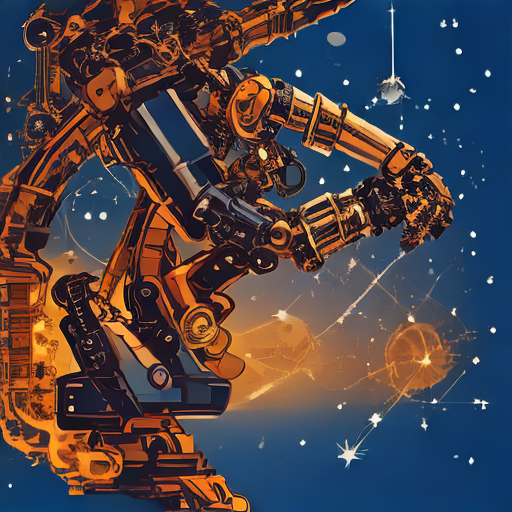

In [15]:
import runpy
_demo=runpy.run_path('lab05_demo.py')
pipe=_demo['pipe']
print('DEMO EXECUTED; GPU',torch.cuda.get_device_name(0))
display(_demo['img'])

## 5 Индивидуальный вариант 3

A — свежий CPU-генератор; B — свежий CUDA-генератор. Seed одинаковый, 1003. Prompt, модель, ревизия, GPU вычислений, fp16, один шаг и guidance=0 совпадают. Сохраняем отдельные PNG и полные манифесты. Затем выполняем штатную `variant_summary(pipe,3)` и сопоставляем её результаты с нашей парой.

PROMPT editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people
{
  "sha_a": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "sha_b": "4675318261e6f52dde480c450f4ecd10b4098544949930eed1c25179474f1e83",
  "pixel_equal": false,
  "max_diff": 255,
  "mse": 7301.234217325847,
  "psnr": 9.496840804095045,
  "verdict": "different"
}
STANDARD SUMMARY MATCHES SAVED A/B


**Слева A: генератор CPU. Справа B: генератор CUDA.**

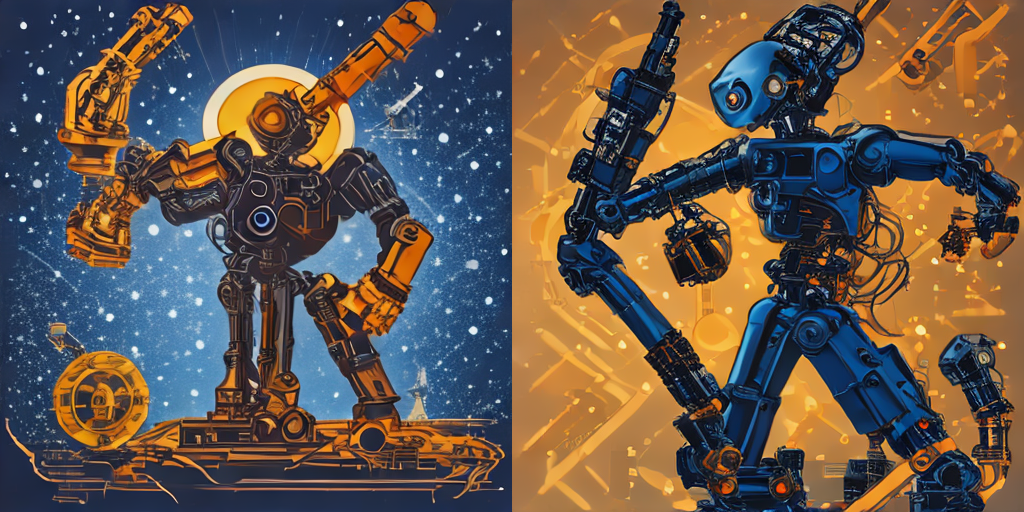

In [16]:
PROMPT=L.BRIEFS[0];SEED=1003
print('PROMPT',PROMPT)
a,b=L.make_pair(pipe,PROMPT,SEED,'generator_device')
manifest_a=save_run('A_cpu',a,'cpu');manifest_b=save_run('B_cuda',b,'cuda')
main_comparison=compare_images(a,b)
write_json(OUT/'comparison_main.json',main_comparison)
print(json.dumps(main_comparison,ensure_ascii=False,indent=2))
standard_summary=L.variant_summary(pipe,3)
assert standard_summary['sha_a']==main_comparison['sha_a']
assert standard_summary['sha_b']==main_comparison['sha_b']
write_json(OUT/'variant_summary.json',standard_summary)
print('STANDARD SUMMARY MATCHES SAVED A/B')
display(Markdown('**Слева A: генератор CPU. Справа B: генератор CUDA.**'))
comparison_montage=montage(a,b);comparison_montage.save(OUT/'comparison_cpu_cuda.png');display(comparison_montage)

## 6 Повтор и ошибка общего генератора

При корректном повторе каждый вызов получает новый генератор с тем же seed. Для воспроизведения ошибки создаём один CPU-генератор и передаём его дважды: после первого вызова его состояние уже изменилось. Проверяем это на своём брифе и seed, а не только в демо.

FRESH GENERATOR {
  "sha_a": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "sha_b": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "pixel_equal": true,
  "max_diff": 0,
  "mse": 0.0,
  "psnr": Infinity,
  "verdict": "identical"
}
SHARED GENERATOR {
  "sha_a": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "sha_b": "0d2ee5df85d53cb0a868122217a1bc1694a7758d17f6501d54e3470efccb826f",
  "pixel_equal": false,
  "max_diff": 254,
  "mse": 6457.283318837483,
  "psnr": 10.030305190015824,
  "verdict": "different"
}


**Общий генератор: первый и второй вызовы.**

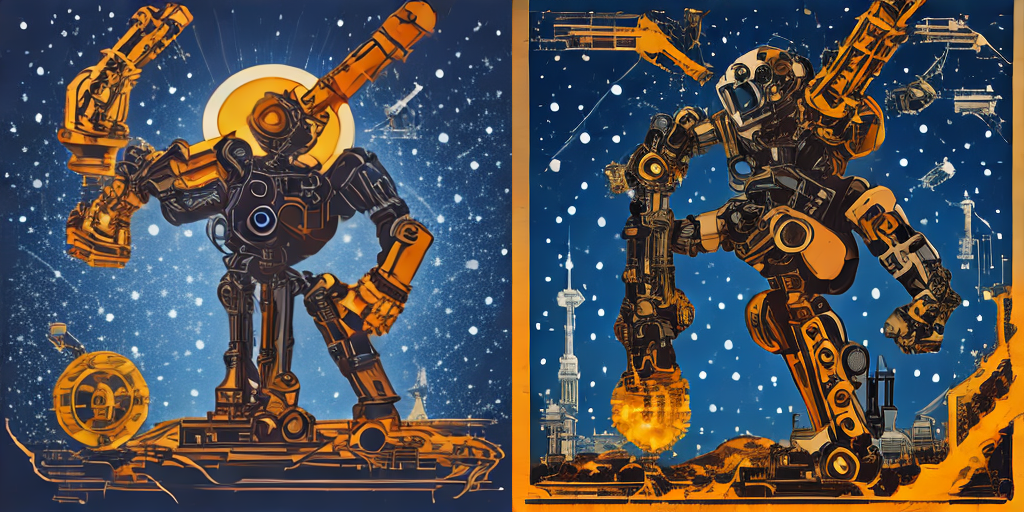

In [17]:
repeat=L.generate(pipe,PROMPT,SEED,gen_device='cpu')[0]
save_run('repeat_fresh_cpu',repeat,'cpu')
repeat_comparison=compare_images(a,repeat)
g=torch.Generator(device='cpu').manual_seed(SEED)
first=pipe(prompt=PROMPT,num_inference_steps=1,guidance_scale=0.0,height=512,width=512,generator=g).images[0]
second=pipe(prompt=PROMPT,num_inference_steps=1,guidance_scale=0.0,height=512,width=512,generator=g).images[0]
save_run('shared_generator_first',first,'cpu',extra={'generator_use':1})
save_run('shared_generator_second',second,'cpu',extra={'generator_use':2})
shared_comparison=compare_images(first,second)
assert np.array_equal(np.asarray(a),np.asarray(first))
assert repeat_comparison['pixel_equal']
write_json(OUT/'comparison_repeat.json',repeat_comparison)
write_json(OUT/'comparison_shared_generator.json',shared_comparison)
print('FRESH GENERATOR',json.dumps(repeat_comparison,indent=2))
print('SHARED GENERATOR',json.dumps(shared_comparison,indent=2))
display(Markdown('**Общий генератор: первый и второй вызовы.**'))
montage(first,second).save(OUT/'shared_generator_comparison.png');display(montage(first,second))

## 7 Где возникает различие

Проверяем начальные латентные тензоры тем же механизмом `randn_tensor`, который используется конвейером. CPU и CUDA при одном seed сравниваются до сети. Затем дважды передаём один и тот же готовый шум на GPU через `latents`: это контроль, отделяющий генератор от вычислений модели.

In [18]:
shape=(1,pipe.unet.config.in_channels,512//pipe.vae_scale_factor,512//pipe.vae_scale_factor)
cpu_lat=randn_tensor(shape,generator=torch.Generator(device='cpu').manual_seed(SEED),device=torch.device('cuda'),dtype=pipe.unet.dtype)
cuda_lat=randn_tensor(shape,generator=torch.Generator(device='cuda').manual_seed(SEED),device=torch.device('cuda'),dtype=pipe.unet.dtype)
np.save(OUT/'initial_noise_cpu.npy',cpu_lat.float().cpu().numpy())
np.save(OUT/'initial_noise_cuda.npy',cuda_lat.float().cpu().numpy())
noise_comparison=dict(shape=list(shape),dtype=str(pipe.unet.dtype),equal=bool(torch.equal(cpu_lat,cuda_lat)),max_diff=float(torch.max(torch.abs(cpu_lat.float()-cuda_lat.float())).item()),mse=float(torch.mean((cpu_lat.float()-cuda_lat.float())**2).item()))
print('INITIAL NOISE',noise_comparison)
def from_latents(lat):
    return pipe(prompt=PROMPT,num_inference_steps=1,guidance_scale=0.0,height=512,width=512,latents=lat.clone()).images[0]
fixed1=from_latents(cpu_lat);fixed2=from_latents(cpu_lat)
fixed_comparison=compare_images(fixed1,fixed2)
reconstructed=compare_images(a,fixed1)
save_run('fixed_noise_first',fixed1,'explicit_cpu_latents')
save_run('fixed_noise_second',fixed2,'explicit_cpu_latents')
write_json(OUT/'comparison_initial_noise.json',noise_comparison)
write_json(OUT/'comparison_fixed_noise.json',fixed_comparison)
write_json(OUT/'comparison_A_vs_explicit_noise.json',reconstructed)
print('SAME LATENTS REPEAT',json.dumps(fixed_comparison,indent=2))
print('A VS EXPLICIT NOISE',json.dumps(reconstructed,indent=2))
assert not noise_comparison['equal']
assert fixed_comparison['pixel_equal']
assert reconstructed['pixel_equal']

INITIAL NOISE {'shape': [1, 4, 64, 64], 'dtype': 'torch.float16', 'equal': False, 'max_diff': 5.564453125, 'mse': 2.0380618572235107}
SAME LATENTS REPEAT {
  "sha_a": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "sha_b": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "pixel_equal": true,
  "max_diff": 0,
  "mse": 0.0,
  "psnr": Infinity,
  "verdict": "identical"
}
A VS EXPLICIT NOISE {
  "sha_a": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "sha_b": "098ebd438eb3befedd979cf5edc0a71ff403f3ae22a664e1644d4309f93eca08",
  "pixel_equal": true,
  "max_diff": 0,
  "mse": 0.0,
  "psnr": Infinity,
  "verdict": "identical"
}


## 8 Вывод по фактическим данным

Критерий 40 дБ записан до запуска. Он условен: PSNR измеряет численное отличие, а не красоту или точность следования брифу. Побитовое совпадение PNG сильнее, чем практическое совпадение по допуску. Область вывода ограничена конкретной моделью, ревизией, GPU и версиями. Новый независимый сеанс здесь не проверяется и не объявляется воспроизведённым.

In [19]:
checks=dict(fresh_generator_repeat=repeat_comparison['pixel_equal'],initial_noise_differs=not noise_comparison['equal'],fixed_noise_repeat=fixed_comparison['pixel_equal'],explicit_noise_reproduces_A=reconstructed['pixel_equal'],standard_summary_matches=True)
verdict_ru={'identical':'идентичны','close':'практически совпадают','different':'различаются'}
conclusion=f"""# Вывод ЛР5 вариант 3

При одном seed 1003 изображения с генераторами CPU и CUDA {verdict_ru[main_comparison['verdict']]}. PSNR={main_comparison['psnr']:.4f} дБ, максимальная разница={main_comparison['max_diff']}, MSE={main_comparison['mse']:.6f}; пиксели совпадают: {main_comparison['pixel_equal']}.

Начальные тензоры CPU/CUDA совпадают: {noise_comparison['equal']}. Два вызова сети с одним явным тензором совпадают: {fixed_comparison['pixel_equal']}. Контроль воспроизводит A: {reconstructed['pixel_equal']}. Это согласуется с возникновением различий на этапе генерации шума при неизменных вычислениях модели.

Свежий CPU-генератор воспроизводит A: {repeat_comparison['pixel_equal']}. Два вызова с общим генератором совпадают: {shared_comparison['pixel_equal']}, PSNR={shared_comparison['psnr']:.4f} дБ. Исправление — новый генератор с тем же seed на каждый независимый запуск.

Гипотеза о PSNR ниже 40 дБ: {main_comparison['psnr']<40}. Визуальная оценка соответствия брифу выполняется отдельно после осмотра пары A/B. Воспроизводимость между другими видеокартами и версиями не доказана.
"""
(OUT/'conclusion.md').write_text(conclusion,encoding='utf8');display(Markdown(conclusion))
write_json(OUT/'checks.json',checks)
print('ALL NUMERICAL CHECKS PASS',all(checks.values()))
assert all(checks.values())

# Вывод ЛР5 вариант 3

При одном seed 1003 изображения с генераторами CPU и CUDA различаются. PSNR=9.4968 дБ, максимальная разница=255, MSE=7301.234217; пиксели совпадают: False.

Начальные тензоры CPU/CUDA совпадают: False. Два вызова сети с одним явным тензором совпадают: True. Контроль воспроизводит A: True. Это согласуется с возникновением различий на этапе генерации шума при неизменных вычислениях модели.

Свежий CPU-генератор воспроизводит A: True. Два вызова с общим генератором совпадают: False, PSNR=10.0303 дБ. Исправление — новый генератор с тем же seed на каждый независимый запуск.

Гипотеза о PSNR ниже 40 дБ: True. Визуальная оценка соответствия брифу выполняется отдельно после осмотра пары A/B. Воспроизводимость между другими видеокартами и версиями не доказана.


ALL NUMERICAL CHECKS PASS True


## 9 Контрольные вопросы

1. Модель — веса и архитектура; конвейер объединяет кодировщик текста, сеть шумоподавления, декодер и планировщик; приложение предоставляет интерфейс.
2. Имя без ревизии может указывать на изменившиеся файлы. Полный commit фиксирует снимок.
3. Seed задаёт начальное состояние конкретного генератора, но не фиксирует его алгоритм на другом устройстве, версии и все недетерминированные операции.
4. CPU-генератор облегчает воспроизводимость начального шума при разных устройствах вычислений; полной межплатформенной гарантии это не даёт.
5. Генератор хранит состояние и потребляет последовательность случайных чисел. Второй вызов продолжает последовательность. Фактическая проверка приведена выше.
6. Равный SHA-256 подтверждает равенство байтов с практически пренебрежимой вероятностью коллизии. Он не доказывает качество изображения или повторяемость в другой среде. Разные файлы могут содержать одинаковые пиксели.
7. PSNR=10log10(65025/65.025)=30 дБ.
8. Может измениться как точность вычислений, так и шум, генерируемый непосредственно в float16/float32. Контроль — сформировать один шум в float32 и приводить его к нужному dtype.
9. Используются открыто доступные веса, но условия лицензии не равны отсутствию ограничений. Учебный некоммерческий запуск документирован; ссылки на карточку и LICENSE закреплены ниже. Перед иным использованием нужны применимые условия.
10. Обновить GPU, драйвер, CUDA, PyTorch и зависимости, параметры детерминизма, время и манифесты; сравнение повторить и не переносить прежний вердикт автоматически.

## 10 Паспорт и комплект

Модель: [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo/tree/b261bac6fd2cf515557d5d0707481eafa0485ec2). [Лицензия закреплённой ревизии](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/LICENSE.md). Веса предоставлены Stability AI; исходники преподавателя и собственный эксперимент разделены. Запрос синтетический, без реальных людей и логотипов.

Архив содержит PNG и manifest.json для всех условий, начальные тензоры, таблицы сравнения, паспорт и версии. Скачанный ноутбук дополнительно сохраняет код, пояснения и выводы. Файлы преподавательского демо из исходного ZIP не выдаются за наш эксперимент.

In [20]:
passport=dict(student='Власюк Данил Витальевич',group='Т26ИИКТ-МИК11',variant=3,started_utc=STARTED_UTC,finished_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),model_id=L.MODEL_ID,revision=L.REVISION,prompt=PROMPT,seed=SEED,steps=1,guidance_scale=0.0,size=[512,512],dtype=str(pipe.unet.dtype),generator_devices=['cpu','cuda'],model_device=torch.cuda.get_device_name(0),gpu_info=GPU_INFO,platform=platform.platform(),python=sys.version,packages=PACKAGES,tolerance_db=40,deterministic_algorithms=torch.are_deterministic_algorithms_enabled(),library_sha256=hashlib.sha256(pathlib.Path('lab05_lib.py').read_bytes()).hexdigest(),demo_sha256=hashlib.sha256(pathlib.Path('lab05_demo.py').read_bytes()).hexdigest(),main_result=main_comparison,checks=checks,independent_new_session_tested=False)
write_json(OUT/'passport.json',passport)
(OUT/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True),encoding='utf8')
import shutil
shutil.copy2('lab05_lib.py',OUT/'lab05_lib.py');shutil.copy2('lab05_demo.py',OUT/'lab05_demo.py')
archive=shutil.make_archive('LR05_variant3_results','zip',OUT)
print('COMPLETE; ARCHIVE',archive)
from google.colab import files
files.download(archive)

COMPLETE; ARCHIVE /content/LR05_variant3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>